In [51]:
from google.colab import files
uploaded = files.upload()

Saving Combined12.csv to Combined12 (4).csv


In [52]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

from imblearn.over_sampling import SMOTE, RandomOverSampler

In [53]:
df = pd.read_csv('/content/Combined12.csv')

df.head()

,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


In [54]:
print("Rows and Columns:", df.shape)

Rows and Columns: (533312, 8)


In [55]:
df.describe(include='all')

,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
count,533312.000000,533312.000000,533312.000000,533312.000000,533312.000000,533312.000000,533312.000000,533312.000000
mean,1011.436192,1.310346,12.646057,8.648474,16.871960,11.885974,192.501742,0.906152
std,3.241187,0.897191,6.519240,5.867740,7.692881,7.677086,101.984936,0.992549
min,971.500000,0.030000,-11.100000,-16.000000,-8.500000,0.000000,0.000000,0.000000
25%,1009.800000,0.510000,7.800000,4.500000,11.100000,6.410000,130.000000,0.000000
50%,1012.300000,1.160000,13.200000,9.400000,17.200000,11.040000,190.000000,1.000000
75%,1013.900000,2.010000,17.500000,13.300000,22.400000,15.620000,288.000000,2.000000
max,1015.000000,3.600000,28.600000,22.000000,37.000000,47.530000,359.000000,3.000000


In [56]:
print(df.isnull().sum())

Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0
dtype: int64


In [57]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer

# Numerical columns
num_cols = df.select_dtypes(include=np.number).columns

num_imputer = SimpleImputer(strategy='mean')
# Ensure there are numerical columns to impute
if not num_cols.empty:
    df[num_cols] = num_imputer.fit_transform(df[num_cols])

# Categorical columns
cat_cols = df.select_dtypes(include='object').columns

cat_imputer = SimpleImputer(strategy='most_frequent')
# Ensure there are categorical columns to impute
if not cat_cols.empty:
    df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])

print(df.isnull().sum())

Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0
dtype: int64


In [58]:
print("Duplicates Before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates After:", df.duplicated().sum())

Duplicates Before: 16264
Duplicates After: 0


In [59]:
le = LabelEncoder()

for col in cat_cols:
    df[col] = le.fit_transform(df[col].astype(str))

df.head()

,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0.0,0.0
1,972.3,0.97,10.5,6.7,13.5,0.0,0.0,0.0
2,972.4,0.74,6.5,3.9,9.1,0.0,0.0,0.0
3,973.2,0.15,5.1,3.7,7.7,0.0,0.0,0.0
4,975.7,0.12,5.2,2.6,8.3,0.0,0.0,0.0


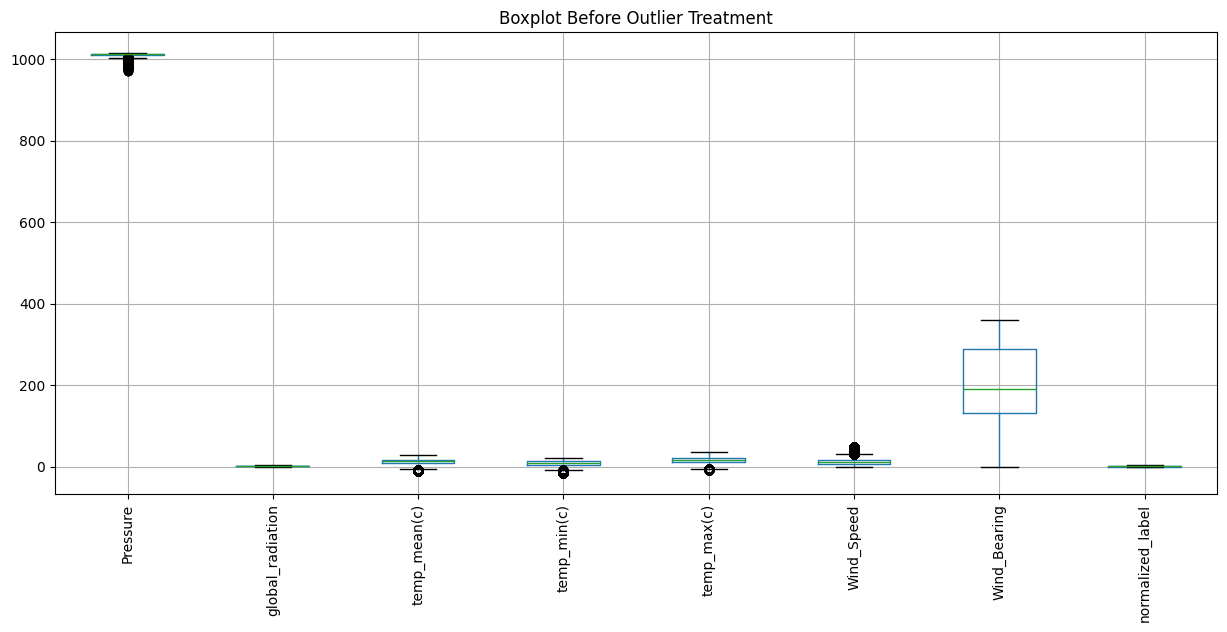

In [60]:
plt.figure(figsize=(15,6))
df.boxplot(rot=90)
plt.title("Boxplot Before Outlier Treatment")
plt.show()

In [61]:
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    df = df[(df[col]>=lower) & (df[col]<=upper)]

print(df.shape)

(443484, 8)


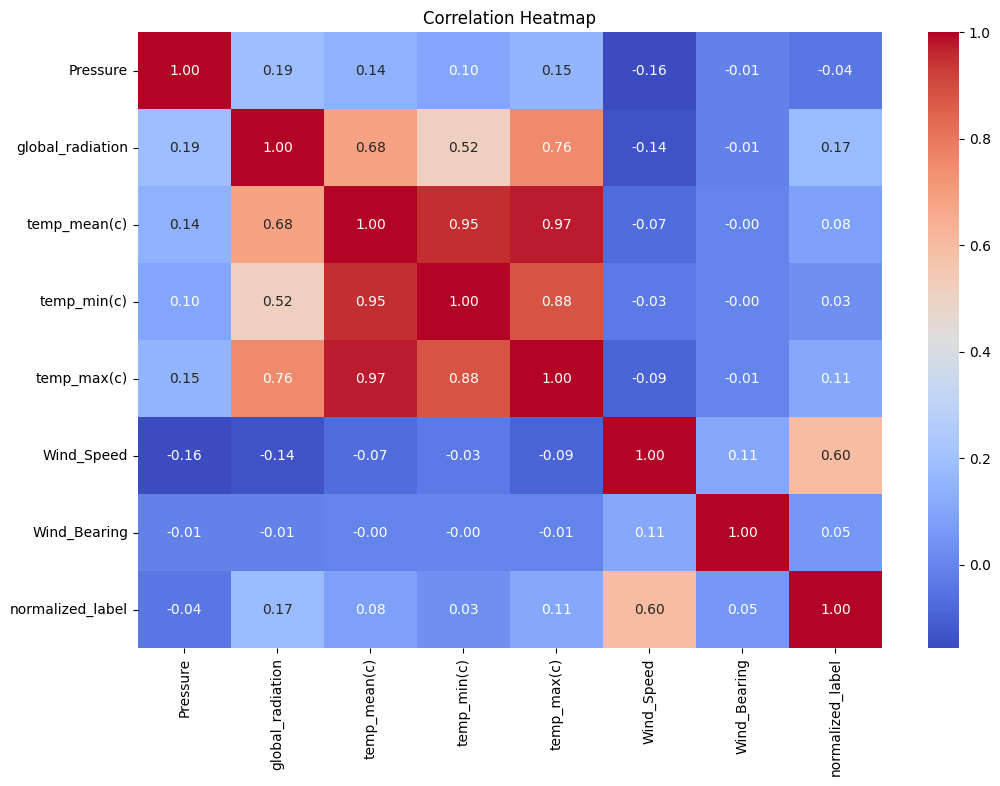

In [42]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12,8))
sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

In [43]:
if len(num_cols) >= 2:
    df["Total_Feature"] = df[num_cols].sum(axis=1)

df.head()

,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label,Total_Feature
15294,1003.7,1.9,17.9,11.6,24.6,10.90,192.0,1.0,1263.60
15296,1003.7,1.9,17.9,11.6,24.6,14.49,150.0,1.0,1225.19
15298,1003.7,1.9,17.9,11.6,24.6,11.27,30.0,1.0,1101.97
15299,1003.7,1.9,17.9,11.6,24.6,11.27,90.0,1.0,1161.97
15300,1003.7,1.9,17.9,11.6,24.6,6.44,320.0,1.0,1387.14


In [44]:
print(df.dtypes)

# Example conversion
for col in df.columns:

    if "date" in col.lower():
        df[col] = pd.to_datetime(df[col])

print(df.dtypes)

Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing        float64
normalized_label    float64
Total_Feature       float64
dtype: object
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing        float64
normalized_label    float64
Total_Feature       float64
dtype: object


In [45]:
# Remove leading/trailing spaces

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Convert text to lowercase

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.lower()

print(df.head())

       Pressure  global_radiation  temp_mean(c)  temp_min(c)  temp_max(c)  \
15294    1003.7               1.9          17.9         11.6         24.6   
15296    1003.7               1.9          17.9         11.6         24.6   
15298    1003.7               1.9          17.9         11.6         24.6   
15299    1003.7               1.9          17.9         11.6         24.6   
15300    1003.7               1.9          17.9         11.6         24.6   

       Wind_Speed  Wind_Bearing  normalized_label  Total_Feature  
15294       10.90         192.0               1.0        1263.60  
15296       14.49         150.0               1.0        1225.19  
15298       11.27          30.0               1.0        1101.97  
15299       11.27          90.0               1.0        1161.97  
15300        6.44         320.0               1.0        1387.14  


In [46]:
X = df.drop('normalized_label', axis=1)
y = df['normalized_label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(354787, 8)
(88697, 8)


In [62]:
import pandas as pd

print("Class Distribution Before")

# Explicitly cast y_train to integer type to ensure it's treated as discrete classes.
# This resolves the 'Unknown label type: continuous' error for SMOTE/RandomOverSampler.
y_train_processed = y_train.astype(int)

print(y_train_processed.value_counts())

try:
    smote = SMOTE(random_state=42)

    X_train_balanced, y_train_balanced = smote.fit_resample(
        X_train,
        y_train_processed
    )

    print("After SMOTE")
    print(pd.Series(y_train_balanced).value_counts())

except Exception as e:
    print(f"SMOTE cannot be applied. Reason: {e}")
    print("Using RandomOverSampler as a fallback.")

    ros = RandomOverSampler(random_state=42)

    X_train_balanced, y_train_balanced = ros.fit_resample(
        X_train,
        y_train_processed
    )

    print(pd.Series(y_train_balanced).value_counts())

Class Distribution Before
normalized_label
0    179088
1    117980
2     57719
Name: count, dtype: int64
After SMOTE
normalized_label
0    179088
1    179088
2    179088
Name: count, dtype: int64


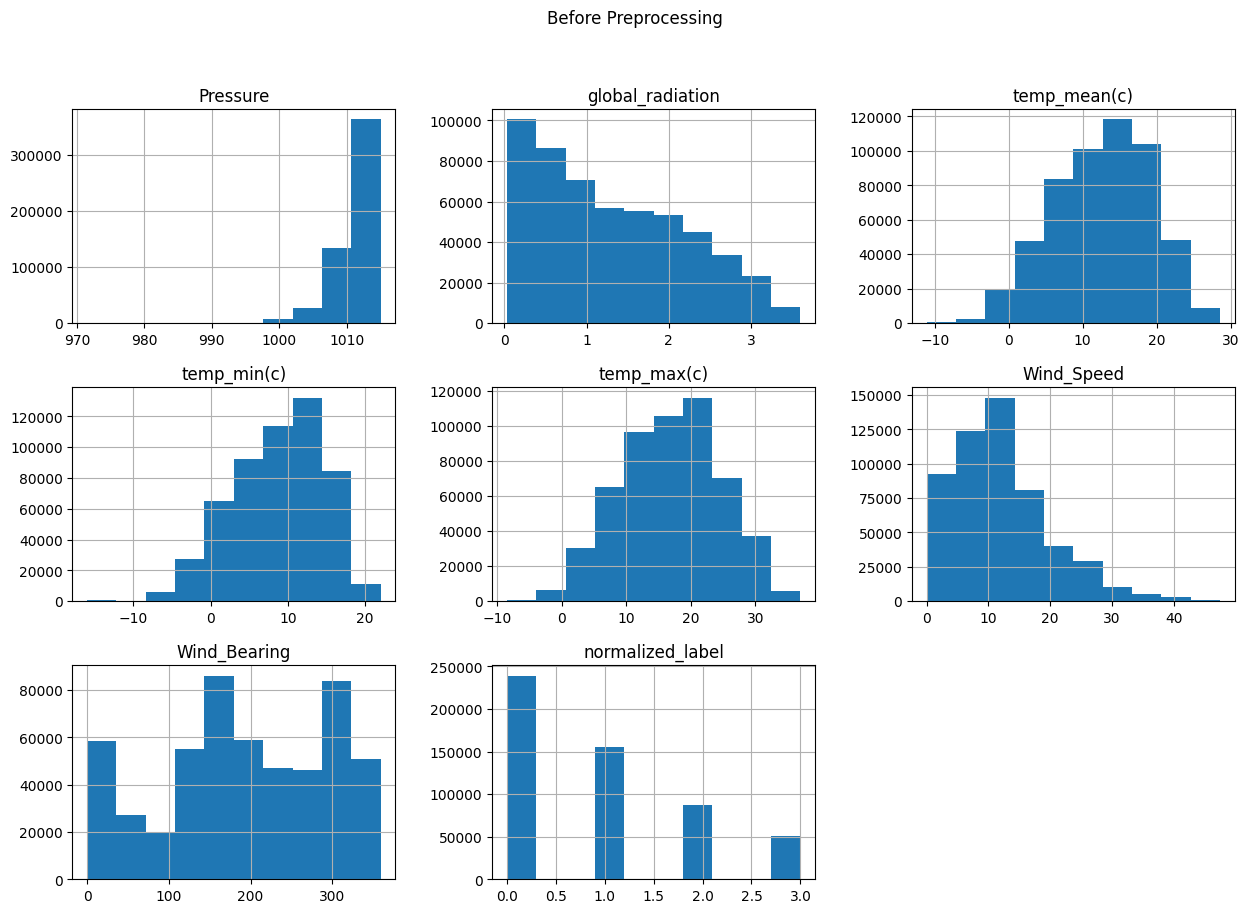

In [47]:
df_original = pd.read_csv('/content/Combined12.csv')

df_original.hist(figsize=(15,10))
plt.suptitle("Before Preprocessing")
plt.show()

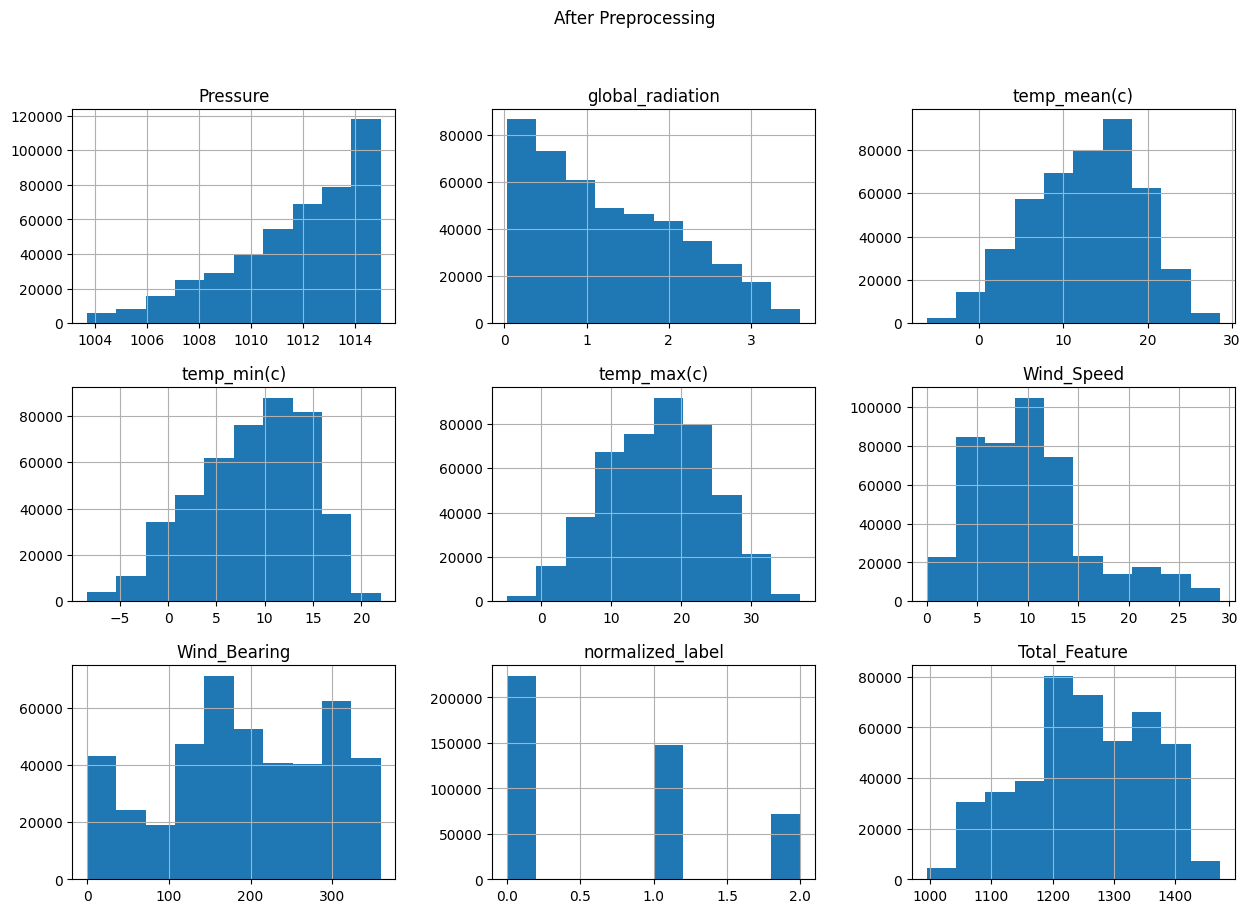

In [48]:
df.hist(figsize=(15,10))
plt.suptitle("After Preprocessing")
plt.show()

In [49]:
comparison = pd.DataFrame({
    "Before": [
        df_original.shape[0],
        df_original.shape[1],
        df_original.isnull().sum().sum(),
        df_original.duplicated().sum()
    ],

    "After": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]

},

index=[
    "Rows",
    "Columns",
    "Missing Values",
    "Duplicate Rows"
])

comparison

,Before,After
Rows,533312,443484
Columns,8,9
Missing Values,0,0
Duplicate Rows,16264,0


In [64]:
df.to_csv("Cleaned_Preprocessed_Dataset.csv", index=False)

print("Dataset Saved Successfully")
from google.colab import files
files.download("Cleaned_Preprocessed_Dataset.csv")

Dataset Saved Successfully


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>